# Fashion-MNIST: self-training trajectories

Compare pullover (label 2, encoded as −1) versus coat (label 4, encoded as +1). The experiment follows the oracle midpoint comparison in `MNIST.ipynb`, with an additional finite fitted-Gaussian run between Fashion-MNIST and the effective process.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "src" / "algorithms.py").is_file()
     and (path / "experiments" / "__init__.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the project checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from experiments.fashion_mnist import FashionMNISTExperiment, describe_fashion_mnist, load_fashion_mnist
from experiments.plotting import experiment_plot_style

DATA_DIR = ROOT / "data" / "fashion_mnist"

## Load the training and test splits

Use the separate train and test IDX files from [Zalando Research](https://github.com/zalandoresearch/fashion-mnist#get-the-data). Cache the original files under `data/fashion_mnist/` and check the published checksums. Flatten each image to 784 pixels and scale the pixel values by 255, as in MNIST.

In [2]:
X_train, y_train = load_fashion_mnist("train", 60_000, DATA_DIR)
X_test, y_test = load_fashion_mnist("t10k", 10_000, DATA_DIR)
data = (X_train, y_train, X_test, y_test)

In [3]:
describe_fashion_mnist(data, DATA_DIR)

Cache: /Users/thierryrioual/Desktop/Princeton/Academics/Research/High-dimensional dynamics of ST/implementation/data/fashion_mnist
Training: 60,000 | Test: 10,000
Features: shape=(60000, 784), dtype=float32


## Binary Fashion-MNIST trajectories from random initialization

Compare self-training on the real images, self-training on a finite sample from the calibrated Gaussian mixture, and the effective process for the same mixture.

In [4]:
# Experiment configuration
save_csv = False  # Set to True to export per-iteration measurements.
negative_label = 2  # pullover
positive_label = 4  # coat
class_proportions = [0.5, 0.2]
labeling_rate = 0.01

n_train = 6000
n_test = 1000
seeds = [42, 43, 44]

training_steps = 200
eta = 0.05
reg_lambda = 0.1
pi = 5.0
tau = 0.8

# Effective-process simulation
sample_particles = 2000  # same budget as the MNIST notebook
particle_seed = 47      # added to the repetition seed, as in the paper's simulations

In [5]:
experiment = FashionMNISTExperiment(
    ROOT, data,
    negative_label=negative_label,
    positive_label=positive_label,
    class_proportions=class_proportions,
    labeling_rate=labeling_rate,
    n_train=n_train,
    n_test=n_test,
    seeds=seeds,
    training_steps=training_steps,
    eta=eta,
    reg_lambda=reg_lambda,
    pi=pi,
    tau=tau,
    sample_particles=sample_particles,
    particle_seed=particle_seed,
)

### Sampling and centering

For a split of size $n$ with target positive proportion $p$, sample $\lfloor np+1/2\rfloor$ positive rows without replacement. Use the official training and test splits separately. Reveal labels in the same proportions as the training pool.

Estimate class means from the scaled training pixels and subtract their midpoint from train and test images, as in the MNIST Gaussian comparison. All 784 features are retained. Hidden training labels determine the oracle midpoint and pooled within-class noise scale. The finite learners receive only the revealed labels.

### Fitting and diagnostics

Start each trajectory at the same $b_0=0$ and seeded $w_0\sim\mathcal N(0,I_d)$. The finite Gaussian design uses the same class and revelation indicators as Fashion-MNIST with independent Gaussian noise. Its independent test noise is drawn using the Fashion-MNIST test labels as fixed class assignments so that both finite test samples have the same class counts.

The two finite methods report class-weighted empirical test error. The recursion reports Gaussian population test error for the same target proportion. All three report selection coverage and incorrectly selected fraction over all unlabeled training points or particles. The half-gap uses the held-out class mean scores for finite runs and signal alignment for the effective process. Record iterations 0 through $T$.

### Calibrate and compare

### Run the comparison and plot the trajectories

Lines show means and shading shows ± one standard deviation across repetitions. The shading describes variation across repetitions.

In [11]:
gaussian_comparison_runs = experiment.run_gaussian_comparison()

| Target p | Seed | d | n | Classes (− / +) | Revealed (− / +) | Sigma | ‖μ‖²/d | Initialization | Centering |
|---:|---:|---:|---:|:---:|:---:|---:|---:|:---|:---|
| 0.5 | 42 | 784 | 6000 | 3000 / 3000 | 30 / 30 | 0.2408 | 1.5319 | Seeded Gaussian weights, zero intercept | Oracle midpoint |
| 0.5 | 43 | 784 | 6000 | 3000 / 3000 | 30 / 30 | 0.2400 | 1.5181 | Seeded Gaussian weights, zero intercept | Oracle midpoint |
| 0.5 | 44 | 784 | 6000 | 3000 / 3000 | 30 / 30 | 0.2406 | 1.5188 | Seeded Gaussian weights, zero intercept | Oracle midpoint |
| 0.2 | 42 | 784 | 6000 | 4800 / 1200 | 48 / 12 | 0.2445 | 1.4826 | Seeded Gaussian weights, zero intercept | Oracle midpoint |
| 0.2 | 43 | 784 | 6000 | 4800 / 1200 | 48 / 12 | 0.2447 | 1.6265 | Seeded Gaussian weights, zero intercept | Oracle midpoint |
| 0.2 | 44 | 784 | 6000 | 4800 / 1200 | 48 / 12 | 0.2442 | 1.7022 | Seeded Gaussian weights, zero intercept | Oracle midpoint |

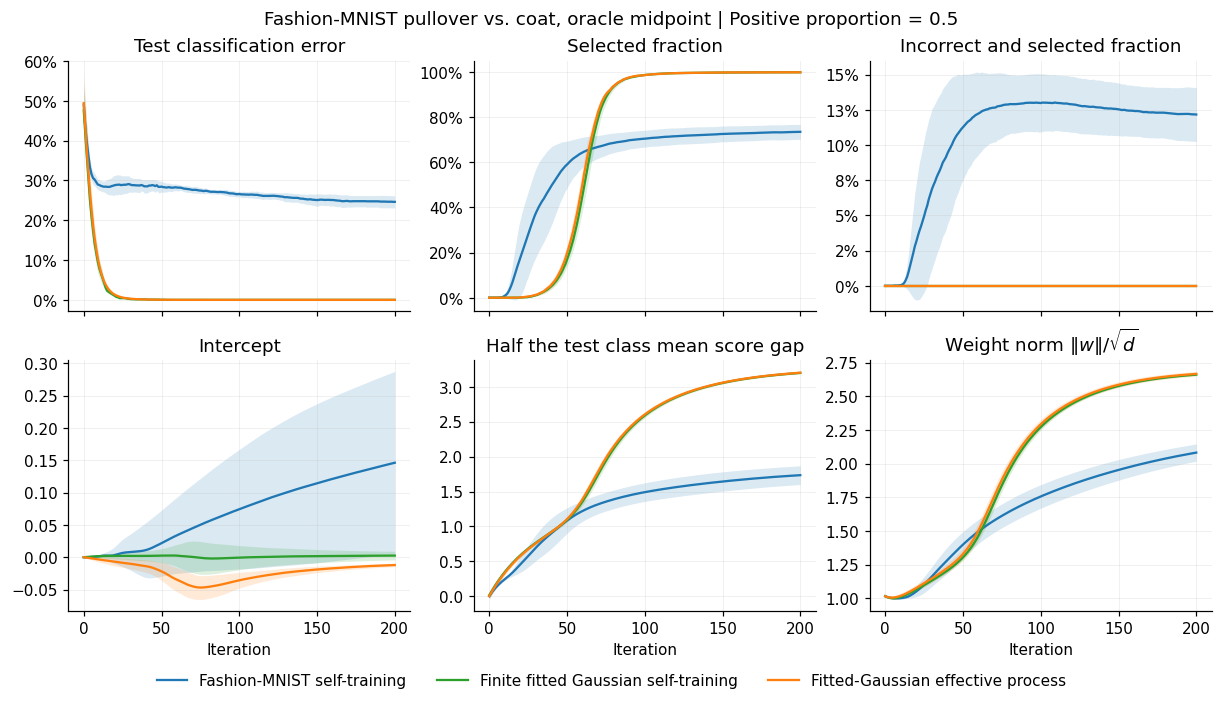

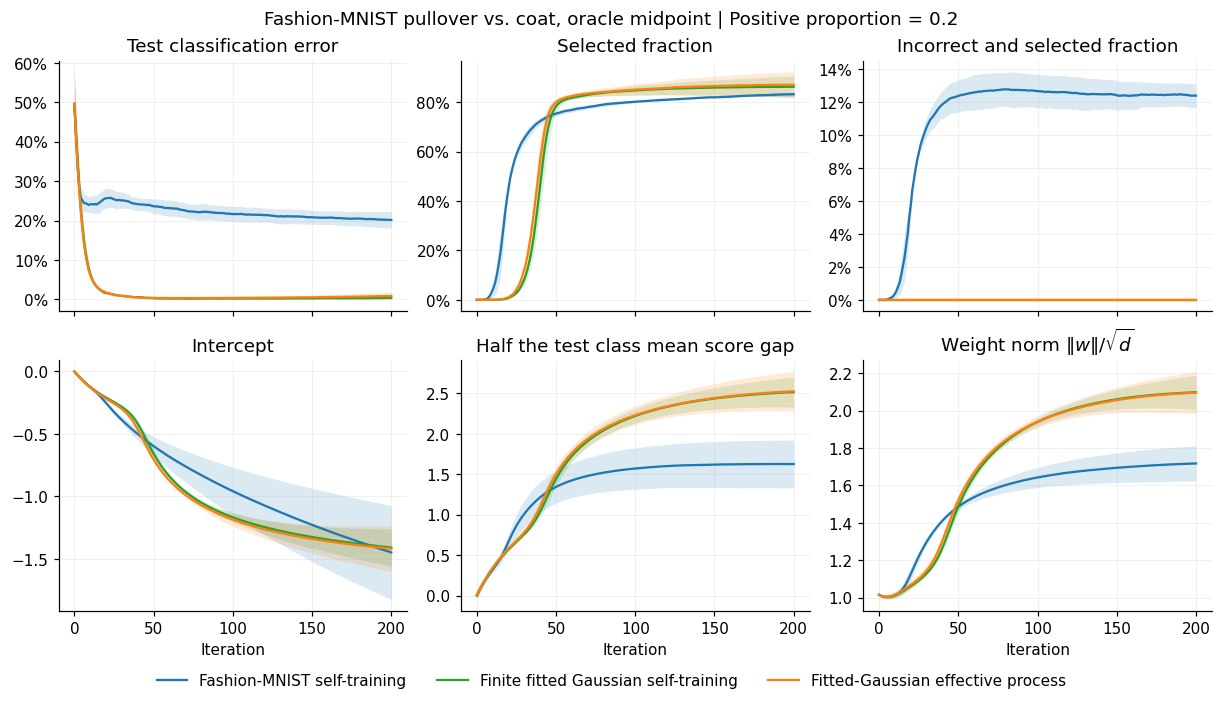

In [12]:
with experiment_plot_style():
    experiment.show_gaussian_figures(gaussian_comparison_runs)

In [13]:
measurements_path = ROOT / "outputs" / "fashion_mnist_self_training" / "gaussian_midpoint_trajectories.csv"
summary, measurements = experiment.save_fashion_mnist_trajectories(gaussian_comparison_runs, measurements_path, save_csv=save_csv)

| Requested p | Method | Initial test error | Final test error | Final selected fraction |
|---:|---:|---:|---:|---:|
| 0.5 | fashion mnist | 49.07% | 24.63% | 73.41% |
| 0.5 | finite gaussian | 47.63% | 0.00% | 99.76% |
| 0.5 | effective process | 49.44% | 0.00% | 99.75% |
| 0.2 | fashion mnist | 49.47% | 20.17% | 83.22% |
| 0.2 | finite gaussian | 48.70% | 0.40% | 86.25% |
| 0.2 | effective process | 49.69% | 0.86% | 87.04% |

Per-iteration measurements saved to /Users/thierryrioual/Desktop/Princeton/Academics/Research/High-dimensional dynamics of ST/implementation/outputs/fashion_mnist_self_training/gaussian_midpoint_trajectories.csv


## Class-specific whitening versus the fitted-Gaussian effective process

Use one residual whitener per class, as in the MNIST notebook. As before, estimate everything on the training pool. Let $A$ be the pooled whitener, $c$ the class midpoint, $m_y$ the class mean, and $A_y=(\widehat\Sigma_y+\epsilon I)^{-1/2}$ the whitener fitted within class $y$. Use the same ridge $\epsilon$ as the pooled run. Transform an image of class $y$ to
$$
A_y(x-m_y)+A(m_y-c).
$$
The training class means remain exactly those of the pooled-whitening experiment, so the half-difference is $A(m_+-m_-)/2$. There is no new signal parameter to choose. Refit the Gaussian noise scale in the new coordinates, since the residual variances can change.

This is an oracle comparison: the true garment label selects the residual transform for each image, including unlabeled and test images. Test observations are excluded from estimating the transforms. The learner, particle recursion, splits, and seeds are the same as in the midpoint-only comparison. Compute the pooled transform as a reference for the covariance gap.

The table reports the relative training class covariance difference $\|C_+-C_-\|_F/\|(C_++C_-)/2\|_F$ under both transforms. Smaller values mean the class covariances are closer.

In [14]:
# Whitening ridge relative to the mean within-class pixel variance.
whitening_ridge_fraction = 0.01

In [16]:
class_whitened_gaussian_runs = experiment.run_class_whitening(whitening_ridge_fraction)

| Target p | Seed | Covariance gap, pooled | Covariance gap, class-specific | Fitted σ |
|---:|---:|---:|---:|---:|
| 0.5 | 42 | 1.066 | 0.277 | 0.803 |
| 0.5 | 43 | 1.068 | 0.274 | 0.803 |
| 0.5 | 44 | 1.067 | 0.279 | 0.802 |
| 0.2 | 42 | 1.186 | 0.355 | 0.807 |
| 0.2 | 43 | 1.197 | 0.353 | 0.806 |
| 0.2 | 44 | 1.189 | 0.344 | 0.807 |

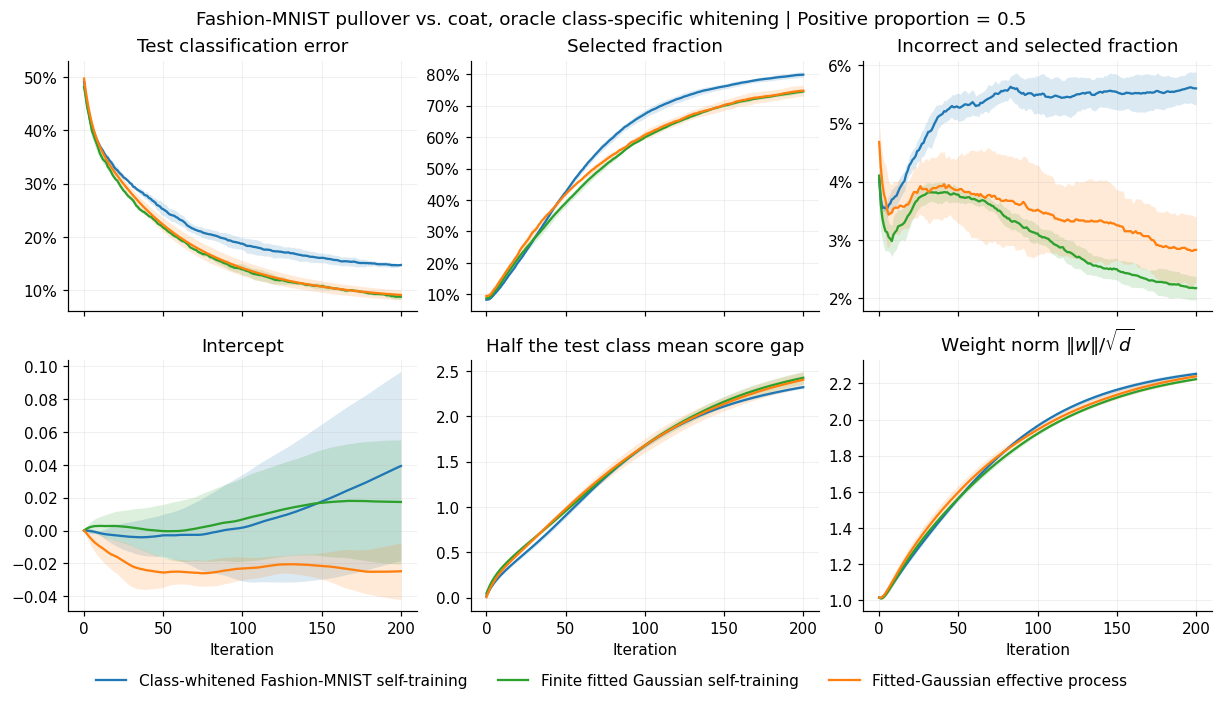

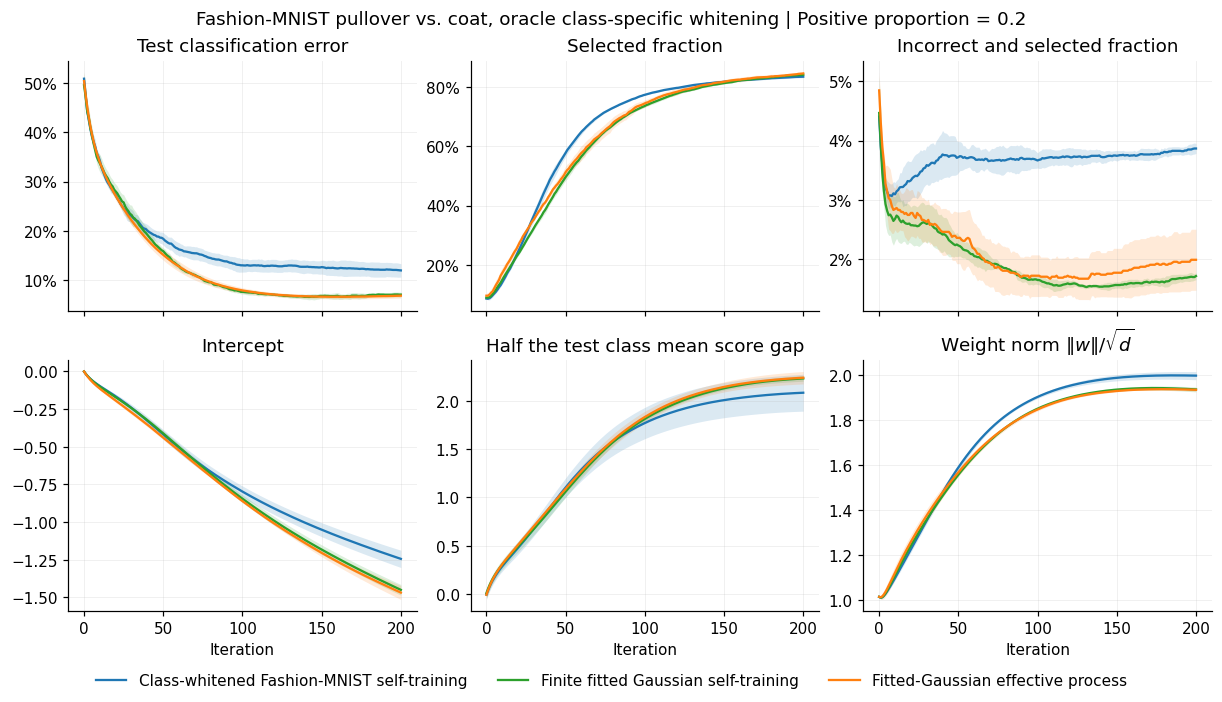

In [17]:
with experiment_plot_style():
    experiment.show_class_whitening_figures(class_whitened_gaussian_runs)

In [18]:
class_whitened_measurements_path = (
    ROOT / "outputs" / "fashion_mnist_self_training" / "gaussian_class_whitened_trajectories.csv"
)
class_whitened_summary, class_whitened_measurements = experiment.save_fashion_mnist_trajectories(
    class_whitened_gaussian_runs, class_whitened_measurements_path, save_csv=save_csv,
)

| Requested p | Method | Initial test error | Final test error | Final selected fraction |
|---:|---:|---:|---:|---:|
| 0.5 | fashion mnist | 49.10% | 14.73% | 79.81% |
| 0.5 | finite gaussian | 48.13% | 8.77% | 74.48% |
| 0.5 | effective process | 49.71% | 9.10% | 74.75% |
| 0.2 | fashion mnist | 50.83% | 12.03% | 83.55% |
| 0.2 | finite gaussian | 49.50% | 7.13% | 84.19% |
| 0.2 | effective process | 50.35% | 6.92% | 84.65% |

Per-iteration measurements saved to /Users/thierryrioual/Desktop/Princeton/Academics/Research/High-dimensional dynamics of ST/implementation/outputs/fashion_mnist_self_training/gaussian_class_whitened_trajectories.csv
